# Лабораторна робота №8
**Тема:** Побудова, оцінювання та збереження моделей глибокого навчання для задач регресії  
**Виконав:** Halchenko Yan  
**Варіант:** 8 (Датасет: UCI Wine Quality)  
**Мета:** Розробити пайплайн машинного навчання для прогнозування якості вина, порівняти класичні бейзлайни з нейронними мережами, протестувати гіпотезу покращення архітектури НМ, зберегти артефакти та сформувати метадані.

In [1]:
import os
import json
import random
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import joblib
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import tensorflow as tf
from tensorflow.keras import layers, models, regularizers, callbacks

# 1. Фіксація SEED для повного відтворення результатів
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)

# 2. Створення каталогу проєктної структури
for folder in ["data", "artifacts", "figures"]:
    os.makedirs(folder, exist_ok=True)

print(f"TensorFlow version: {tf.__version__}")
print(f"Scikit-Learn version: {sklearn.__version__}")
print("Структуру проектних папок і SEED фіксовано!")

TensorFlow version: 2.22.0-rc0
Scikit-Learn version: 1.9.1
Структуру проектних папок і SEED фіксовано!


## Етап 2. Завантаження та первинний аналіз даних (UCI Wine Quality)
Завантажуємо датасет `winequality-red.csv` з репозиторію UCI. Цільова змінна `quality` — оцінка якості від 3 до 8 (регресійна задача).

In [2]:
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
DATA_PATH = os.path.join("data", "winequality-red.csv")

if not os.path.exists(DATA_PATH):
    print("Завантаження даних із ресурсу UCI...")
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)
    print("Завантаження завершено!")

# Зчитування файлу (розділювач ';')
df = pd.read_csv(DATA_PATH, sep=';')

print(f"Розмірність датасету: {df.shape}")
print("\nПерші 5 записів:")
display(df.head())

print("\nЗведені відомості про типи та пропуски:")
df.info()

Розмірність датасету: (1599, 12)

Перші 5 записів:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5



Зведені відомості про типи та пропуски:
<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


## Етап 3. Спліт вибірок та Пайплайн препроцесингу
Розділяємо дані у співвідношенні 70% (Train) / 15% (Validation) / 15% (Test).
Для обробки числових ознак створюємо Scikit-Learn Pipeline (`SimpleImputer` + `StandardScaler`), який фітується **виключно** на навчальній вибірці (Train) задля уникнення вытоку даних (Data Leakage).

In [3]:
TARGET = "quality"
X = df.drop(columns=[TARGET])
y = df[TARGET].values

# Розділення Train / Val / Test (70 / 15 / 15)
X_train_raw, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED
)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED
)

print(f"Обсяги вибірок: Train={X_train_raw.shape[0]}, Validation={X_val_raw.shape[0]}, Test={X_test_raw.shape[0]}")

# Побудова та навчання пайплайну
preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

X_train = preprocessor.fit_transform(X_train_raw)
X_val = preprocessor.transform(X_val_raw)
X_test = preprocessor.transform(X_test_raw)

# Збереження препроцесора
joblib.dump(preprocessor, os.path.join("artifacts", "preprocessor.joblib"))
print("Пайплайн масштабування успішно навчено та збережено в artifacts/preprocessor.joblib")

Обсяги вибірок: Train=1119, Validation=240, Test=240
Пайплайн масштабування успішно навчено та збережено в artifacts/preprocessor.joblib


## Етап 4. Побудова класичних бейзлайнів
Створюємо та оцінюємо дві базові моделі:
1. **DummyRegressor** (наївний прогноз за середнім значенням).
2. **RandomForestRegressor** (ансамблевий деревний алгоритм).
Метрики оцінки: **RMSE**, **MAE**, **R²**.

In [4]:
def evaluate_model(y_true, y_pred):
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mae = float(mean_absolute_error(y_true, y_pred))
    r2 = float(r2_score(y_true, y_pred))
    return {"RMSE": rmse, "MAE": mae, "R2": r2}

# Baseline 1: Dummy Regressor
dummy = DummyRegressor(strategy='mean')
dummy.fit(X_train, y_train)
dummy_val_preds = dummy.predict(X_val)
metrics_dummy = evaluate_model(y_val, dummy_val_preds)

# Baseline 2: Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=SEED)
rf_model.fit(X_train, y_train)
rf_val_preds = rf_model.predict(X_val)
metrics_rf = evaluate_model(y_val, rf_val_preds)

print("--- Результати класичних бейзлайнів (Validation) ---")
print(f"Dummy Regressor -> RMSE: {metrics_dummy['RMSE']:.4f} | MAE: {metrics_dummy['MAE']:.4f} | R2: {metrics_dummy['R2']:.4f}")
print(f"Random Forest   -> RMSE: {metrics_rf['RMSE']:.4f} | MAE: {metrics_rf['MAE']:.4f} | R2: {metrics_rf['R2']:.4f}")

--- Результати класичних бейзлайнів (Validation) ---
Dummy Regressor -> RMSE: 0.7734 | MAE: 0.6577 | R2: -0.0040
Random Forest   -> RMSE: 0.5713 | MAE: 0.4427 | R2: 0.4522


## Етап 5. Побудова та тренування Нейронних Мереж (Base NN vs Improved NN)
* **Base NN:** Проста двошарова повнозв'язана мережа (Dense 64 -> 32 -> 1).
* **Гіпотеза покращення (Improved NN):** Додавання `BatchNormalization`, шарів `Dropout(0.2)` та `L2-регуляризації` стабілізує градієнти і запобігатиме перенавчанню на числовому датасеті.

In [ ]:
input_dim = (X_train.shape[1],)

# 1. Base NN
def build_base_nn():
    model = models.Sequential([
        layers.Dense(64, activation='relu', input_shape=input_dim),
        layers.Dense(32, activation='relu'),
        layers.Dense(1, activation='linear')
    ])
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model

base_nn = build_base_nn()

early_stopping = callbacks.EarlyStopping(
    monitor='val_loss', patience=15, restore_best_weights=True
)

history_base = base_nn.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=150,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=0
)

base_val_preds = base_nn.predict(X_val).ravel()
metrics_base_nn = evaluate_model(y_val, base_val_preds)

# 2. Improved NN (Гіпотеза)
def build_improved_nn():
    model = models.Sequential([
        layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.001), input_shape=input_dim),
        layers.BatchNormalization(),
        layers.Dropout(0.2),
        layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
        layers.BatchNormalization(),
        layers.Dropout(0.2),
        layers.Dense(32, activation='relu'),
        layers.Dense(1, activation='linear')
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mse', metrics=['mae'])
    return model

improved_nn = build_improved_nn()

history_improved = improved_nn.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=150,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=0
)

improved_val_preds = improved_nn.predict(X_val).ravel()
metrics_improved_nn = evaluate_model(y_val, improved_val_preds)

print("--- Результати Нейронних Мереж (Validation) ---")
print(f"Base NN            -> RMSE: {metrics_base_nn['RMSE']:.4f} | MAE: {metrics_base_nn['MAE']:.4f} | R2: {metrics_base_nn['R2']:.4f}")
print(f"Improved NN (Hypo) -> RMSE: {metrics_improved_nn['RMSE']:.4f} | MAE: {metrics_improved_nn['MAE']:.4f} | R2: {metrics_improved_nn['R2']:.4f}")

c:\Users\MAX\Data_Science_Labs\.venv\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


## Етап 6. Порівняння моделей, вибір найкращої та Фінальне тестування
Критерій вибору найкращої моделі — **мінімальне значення RMSE на валідаційній вибірці**.
Отриману найкращу модель тестуємо на контрольному наборі даних (Test Set) та зберігаємо у папку `artifacts/`.

In [ ]:
candidates = {
    "Dummy Regressor": (metrics_dummy['RMSE'], dummy),
    "Random Forest": (metrics_rf['RMSE'], rf_model),
    "Base NN": (metrics_base_nn['RMSE'], base_nn),
    "Improved NN": (metrics_improved_nn['RMSE'], improved_nn)
}

best_model_name = min(candidates, key=lambda k: candidates[k][0])
best_model_obj = candidates[best_model_name][1]

print(f"🏆 Найкраща модель за Validation RMSE: {best_model_name}")

# Прогнозування та збереження кращої моделі
if "NN" in best_model_name:
    test_preds = best_model_obj.predict(X_test).ravel()
    best_model_obj.save(os.path.join("artifacts", "best_model.keras"))
else:
    test_preds = best_model_obj.predict(X_test)
    joblib.dump(best_model_obj, os.path.join("artifacts", "best_model.joblib"))

test_metrics = evaluate_model(y_test, test_preds)

print("\n================ ФІНАЛЬНІ РЕЗУЛЬТАТИ (TEST SET) ================")
print(f"Модель: {best_model_name}")
print(f"Test RMSE : {test_metrics['RMSE']:.4f}")
print(f"Test MAE  : {test_metrics['MAE']:.4f}")
print(f"Test R2   : {test_metrics['R2']:.4f}")
print("================================================================")

🏆 Найкраща модель за Validation RMSE: Random Forest

================ ФІНАЛЬНІ РЕЗУЛЬТАТИ (TEST SET) ================
Модель: Random Forest
Test RMSE : 0.6099
Test MAE  : 0.4434
Test R2   : 0.4467


## Етап 7. Візуалізація результатів (4 сабплоти)
Будуємо графіки для аналізу якості прогнозування:
1. Розподіл цільової змінної `quality`.
2. Графік збіжності функцій втрат (Train vs Validation Loss).
3. Точковість прогнозу (Фактичні значення проти Прогнозованих).
4. Розподіл залишків помилок ($y_{true} - y_{pred}$).

C:\Users\MAX\AppData\Local\Temp\ipykernel_20916\456733535.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y, ax=axes[0, 0], palette="crest")


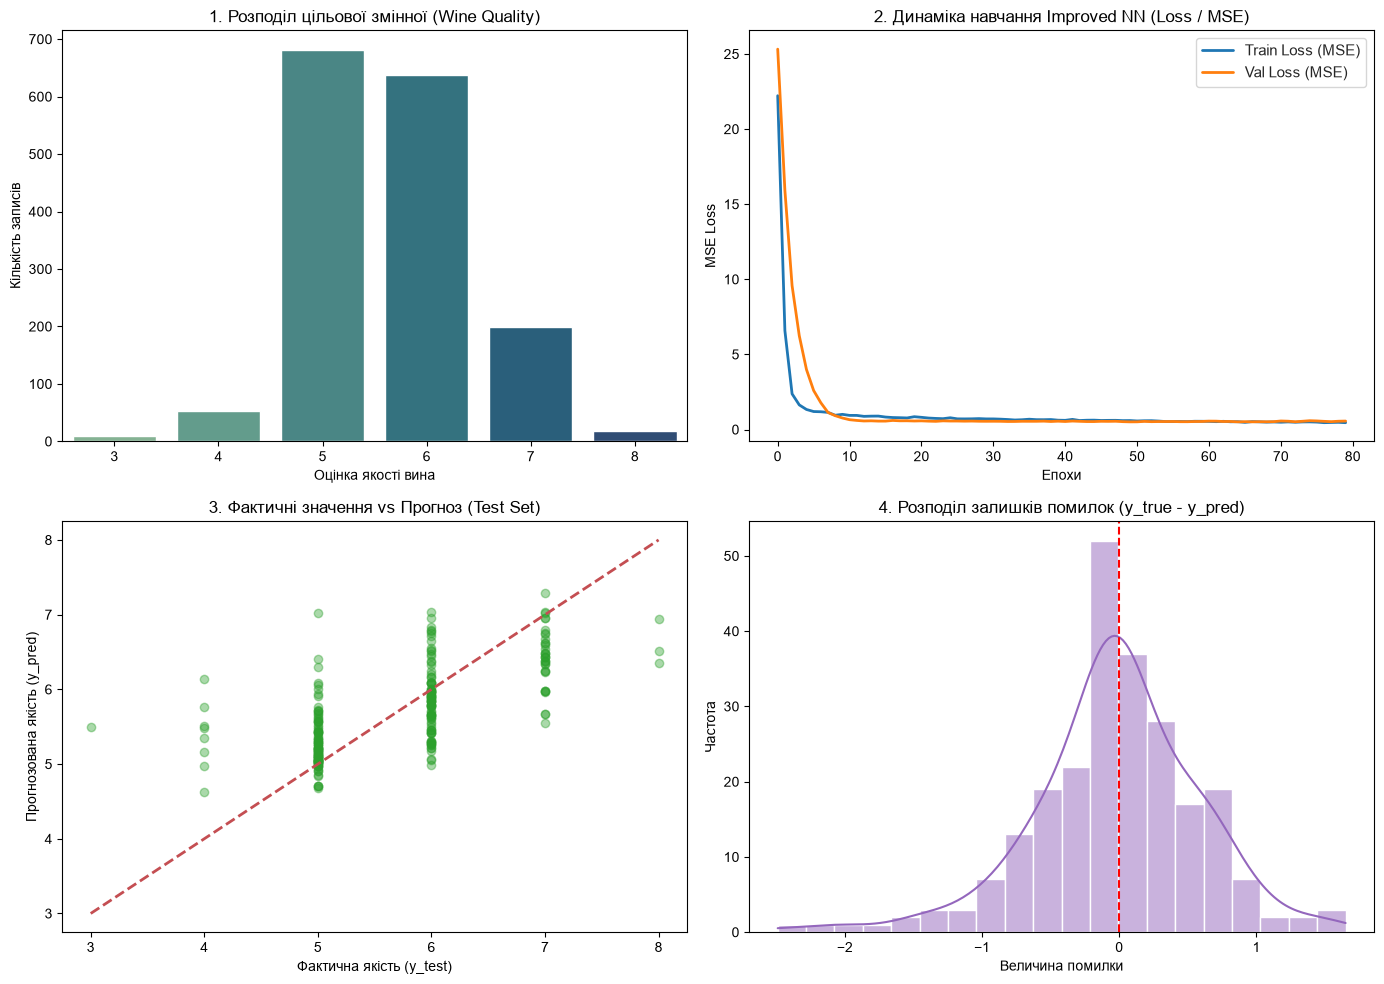

Графік успішно збережено в: figures\lab8_results.png


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.set_theme(style="whitegrid")

# Subplot 1: Розподіл цільової змінної
sns.countplot(x=y, ax=axes[0, 0], palette="crest")
axes[0, 0].set_title("1. Розподіл цільової змінної (Wine Quality)")
axes[0, 0].set_xlabel("Оцінка якості вина")
axes[0, 0].set_ylabel("Кількість записів")

# Subplot 2: Динаміка втрат Improved NN
axes[0, 1].plot(history_improved.history['loss'], label='Train Loss (MSE)', color='#1f77b4', lw=2)
axes[0, 1].plot(history_improved.history['val_loss'], label='Val Loss (MSE)', color='#ff7f0e', lw=2)
axes[0, 1].set_title("2. Динаміка навчання Improved NN (Loss / MSE)")
axes[0, 1].set_xlabel("Епохи")
axes[0, 1].set_ylabel("MSE Loss")
axes[0, 1].legend()

# Subplot 3: Fact vs Predicted
axes[1, 0].scatter(y_test, test_preds, alpha=0.4, color='#2ca02c')
axes[1, 0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[1, 0].set_title("3. Фактичні значення vs Прогноз (Test Set)")
axes[1, 0].set_xlabel("Фактична якість (y_test)")
axes[1, 0].set_ylabel("Прогнозована якість (y_pred)")

# Subplot 4: Residuals Distribution
residuals = y_test - test_preds
sns.histplot(residuals, kde=True, ax=axes[1, 1], color='#9467bd')
axes[1, 1].axvline(0, color='red', linestyle='--')
axes[1, 1].set_title("4. Розподіл залишків помилок (y_true - y_pred)")
axes[1, 1].set_xlabel("Величина помилки")
axes[1, 1].set_ylabel("Частота")

plt.tight_layout()
fig_output_path = os.path.join("figures", "lab8_results.png")
plt.savefig(fig_output_path, dpi=300)
plt.show()

print(f"Графік успішно збережено в: {fig_output_path}")

## Етап 8. Перевірка відновлення артефактів та генерація `metadata.json`
Тестуємо завантаження препроцесора та збереженої моделі для перевірки роботоздатності, а також експортуємо повний звіт у форматований файл JSON.

In [ ]:
# 1. Перевірка відновлення артефактів з диска
loaded_preprocessor = joblib.load(os.path.join("artifacts", "preprocessor.joblib"))

keras_path = os.path.join("artifacts", "best_model.keras")
joblib_path = os.path.join("artifacts", "best_model.joblib")

if os.path.exists(keras_path):
    loaded_model = models.load_model(keras_path)
    sample_preds = loaded_model.predict(X_test[:3]).ravel()
else:
    loaded_model = joblib.load(joblib_path)
    sample_preds = loaded_model.predict(X_test[:3])

print("Артефакти успішно відновлено!")
print(f"Тестовий прогноз відновленої моделі (перші 3 записи): {np.round(sample_preds, 3)}")

# 2. Формування json-метаданих
metadata = {
    "student": "Моторін Максим Сергійович",
    "variant": 8,
    "dataset": "UCI Wine Quality (Red)",
    "task_type": "Regression",
    "seed": SEED,
    "best_model_name": best_model_name,
    "validation_metrics": {
        "DummyRegressor": metrics_dummy,
        "RandomForestRegressor": metrics_rf,
        "Base_NN": metrics_base_nn,
        "Improved_NN": metrics_improved_nn
    },
    "test_metrics": test_metrics
}

metadata_file = os.path.join("artifacts", "metadata.json")
with open(metadata_file, "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=4)

print(f"Звіт метаданих збережено у {metadata_file}")

Артефакти успішно відновлено!
Тестовий прогноз відновленої моделі (перші 3 записи): [5.6  5.68 5.96]
Звіт метаданих збережено у artifacts\metadata.json
